# 1. Hiểu dữ liệu và phân tích khám phá (EDA)

Môn Khai phá dữ liệu. Bộ dữ liệu: *Credit Score Classification* (Kaggle), file `train.csv`.

## Bài toán
Dự đoán điểm tín dụng `Credit_Score` của khách hàng ngân hàng (Poor, Standard hoặc Good) từ hồ sơ tài chính của họ mỗi tháng.

Bài được chia thành 4 notebook, theo thứ tự các bước của quy trình khai phá dữ liệu:

| Notebook | Việc làm | Kết quả |
|---|---|---|
| **1_data_understanding_eda** (notebook này) | Xem và đo dữ liệu | Danh sách lỗi, số liệu chứng minh, kế hoạch làm sạch |
| 2_data_cleaning | Làm sạch | `data/credit_clean.csv` và báo cáo chất lượng |
| 3_post_cleaning_features | Kiểm tra dữ liệu sạch, tạo đặc trưng | `data/credit_features.csv` |
| 4_modeling_evaluation | Mô hình và đánh giá | Mô hình làm sạch giúp được bao nhiêu |

## Notebook này làm gì
Notebook này chỉ xem dữ liệu, không sửa dữ liệu gốc. Mỗi lỗi tìm được đều có số liệu đi kèm, và mọi ngưỡng dùng ở notebook 2 đều lấy từ các con số ở đây chứ không đặt tùy ý. Cuối notebook (mục 1.10) có bảng tóm tắt: lỗi gì, chứng minh bằng gì, xử lý ra sao.

In [1]:
import sys
import warnings
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import credit_cleaning as cc        # chỉ dùng để xem dữ liệu sau khi bỏ giá trị rác, không sửa dữ liệu gốc
from notebook_utils import LABELS, COLORS, setup_style, body_run, effect_numeric, cramers_v

warnings.filterwarnings('ignore')
setup_style()

df = pd.read_csv('../data/train.csv', low_memory=False)
print(f'{df.shape[0]:,} dòng, {df.shape[1]} cột, bộ nhớ {df.memory_usage(deep=True).sum() / 1e6:.0f} MB')
df.head(3).T

100,000 dòng, 28 cột, bộ nhớ 126 MB


,0,1,2
ID,0x1602,0x1603,0x1604
Customer_ID,CUS_0xd40,CUS_0xd40,CUS_0xd40
Month,January,February,March
Name,Aaron Maashoh,Aaron Maashoh,Aaron Maashoh
Age,23,23,-500
SSN,821-00-0265,821-00-0265,821-00-0265
Occupation,Scientist,Scientist,Scientist
Annual_Income,19114.12,19114.12,19114.12
Monthly_Inhand_Salary,1824.843333,NaN,NaN
Num_Bank_Accounts,3,3,3


## 1.1 Từ điển dữ liệu
Đọc ý nghĩa từng cột trước khi phân tích. Cột "hành vi theo thời gian" chỉ là dự đoán ban đầu, sẽ kiểm tra lại ở mục 1.6.

| Cột | Ý nghĩa | Kiểu đúng | Hành vi theo thời gian (dự đoán) |
|---|---|---|---|
| `ID` | Mã bản ghi (khách và tháng) | định danh | duy nhất |
| `Customer_ID` | Mã khách hàng | định danh | không đổi |
| `Month` | Tháng (January đến August) | thứ tự | tăng dần |
| `Name`, `SSN` | Tên, số an sinh xã hội | định danh | không đổi |
| `Age` | Tuổi | số nguyên | gần như không đổi |
| `Occupation` | Nghề nghiệp | phân loại | không đổi |
| `Annual_Income` | Thu nhập năm | số thực | không đổi |
| `Monthly_Inhand_Salary` | Lương thực nhận mỗi tháng | số thực | chưa rõ |
| `Num_Bank_Accounts`, `Num_Credit_Card` | Số tài khoản, số thẻ tín dụng | số nguyên | chưa rõ |
| `Interest_Rate` | Lãi suất (%) | số nguyên | không đổi |
| `Num_of_Loan`, `Type_of_Loan` | Số khoản vay, danh sách loại vay | số nguyên, chuỗi | không đổi |
| `Delay_from_due_date` | Số ngày trễ so với hạn thanh toán | số nguyên | thay đổi theo tháng |
| `Num_of_Delayed_Payment` | Số lần trả chậm | số nguyên | thay đổi theo tháng |
| `Changed_Credit_Limit` | % thay đổi hạn mức tín dụng | số thực | thay đổi theo tháng |
| `Num_Credit_Inquiries` | Số lần truy vấn tín dụng | số nguyên | thay đổi theo tháng |
| `Credit_Mix` | Chất lượng cơ cấu tín dụng (Bad, Standard, Good) | phân loại có thứ tự | không đổi |
| `Outstanding_Debt` | Dư nợ còn lại | số thực | không đổi |
| `Credit_Utilization_Ratio` | Tỷ lệ dùng hạn mức tín dụng (%) | số thực | thay đổi theo tháng |
| `Credit_History_Age` | Tuổi lịch sử tín dụng ("22 Years and 9 Months") | số tháng (đang là chuỗi) | tăng 1 tháng mỗi tháng |
| `Payment_of_Min_Amount` | Có trả mức tối thiểu không (Yes, No, NM) | phân loại | thay đổi theo tháng |
| `Total_EMI_per_month` | Tổng tiền trả góp mỗi tháng | số thực | chưa rõ |
| `Amount_invested_monthly` | Số tiền đầu tư mỗi tháng | số thực | thay đổi theo tháng |
| `Payment_Behaviour` | Thói quen chi tiêu và độ lớn khoản thanh toán | phân loại | thay đổi theo tháng |
| `Monthly_Balance` | Số dư cuối tháng | số thực | thay đổi theo tháng |
| `Credit_Score` | Nhãn cần dự đoán | phân loại có thứ tự | có thể đổi theo tháng |

## 1.2 Cấu trúc dữ liệu: khách hàng nhân với tháng

In [2]:
by_customer = df.groupby('Customer_ID')
valid_ssn = df['SSN'].ne(cc.PLACEHOLDERS['SSN'])

structure = pd.Series({
    'Số dòng': f'{len(df):,}',
    'Số khách hàng': f'{df.Customer_ID.nunique():,}',
    'Số dòng mỗi khách': sorted(by_customer.size().unique()),
    'ID duy nhất': bool(df.ID.is_unique),
    'Số dòng trùng hoàn toàn': int(df.duplicated().sum()),
    'Mọi khách có đủ 8 tháng, đúng thứ tự từ January đến August': bool(by_customer.Month.apply(lambda s: list(s) == cc.MONTHS).all()),
    'Mỗi SSN hợp lệ thuộc đúng 1 khách': bool(df[valid_ssn].groupby('SSN').Customer_ID.nunique().eq(1).all()),
})
structure.to_frame('giá trị')

,giá trị
Số dòng,"100,000"
Số khách hàng,"12,500"
Số dòng mỗi khách,[8]
ID duy nhất,True
Số dòng trùng hoàn toàn,0
"Mọi khách có đủ 8 tháng, đúng thứ tự từ January đến August",True
Mỗi SSN hợp lệ thuộc đúng 1 khách,True


Dữ liệu không phải 100.000 quan sát độc lập mà là 12.500 khách, mỗi khách 8 tháng. Có hai hệ quả:
- Các dòng của cùng một khách rất giống nhau. Khi chia train và test phải chia theo khách, nếu không cùng một người sẽ nằm ở cả hai tập (notebook 4).
- Các tháng còn lại của chính khách đó là nguồn tốt nhất để sửa một ô bị lỗi (notebook 2).

### Nhãn `Credit_Score`

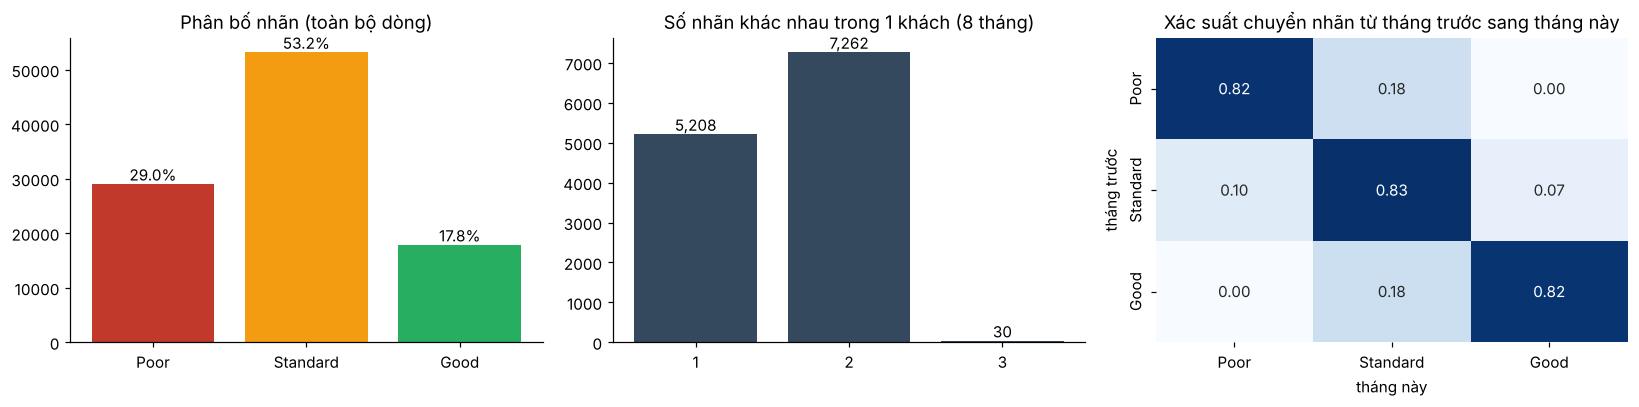

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

# Phân bố nhãn
counts = df.Credit_Score.value_counts().reindex(LABELS)
ax[0].bar(counts.index, counts.values, color=[COLORS[k] for k in counts.index])
ax[0].set_title('Phân bố nhãn (toàn bộ dòng)')
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f'{v / len(df):.1%}', ha='center', va='bottom')

# Mỗi khách có mấy nhãn khác nhau trong 8 tháng
labels_per_customer = by_customer.Credit_Score.nunique().value_counts().sort_index()
ax[1].bar(labels_per_customer.index.astype(str), labels_per_customer.values, color='#34495e')
ax[1].set_title('Số nhãn khác nhau trong 1 khách (8 tháng)')
for i, v in enumerate(labels_per_customer.values):
    ax[1].text(i, v, f'{v:,}', ha='center', va='bottom')

# Xác suất chuyển nhãn từ tháng trước sang tháng này
previous = by_customer.Credit_Score.shift(1)
transition = pd.crosstab(previous, df.Credit_Score, normalize='index').reindex(index=LABELS, columns=LABELS)
sns.heatmap(transition, annot=True, fmt='.2f', cmap='Blues', ax=ax[2], cbar=False)
ax[2].set_title('Xác suất chuyển nhãn từ tháng trước sang tháng này')
ax[2].set_xlabel('tháng này')
ax[2].set_ylabel('tháng trước')

plt.tight_layout()
plt.show()

Nhãn bị lệch lớp: Standard chiếm hơn một nửa, Good chỉ khoảng 18%. Vì vậy khi làm mô hình sẽ dùng macro-F1 làm chỉ số chính và thử `class_weight`.

Nhãn có đổi theo tháng: phần lớn khách có 2 nhãn khác nhau trong 8 tháng. Nhưng nhãn đổi chậm, xác suất giữ nguyên nhãn ở tháng sau đều trên 0,8, và Poor không bao giờ nhảy thẳng sang Good. Vậy bài toán là đoán nhãn cho từng dòng (khách và tháng), không phải một nhãn chung cho cả khách.

## 1.3 Chất lượng dữ liệu, chiều 1: giá trị thiếu

,số ô thiếu,% thiếu
Monthly_Inhand_Salary,15002,15.00
Type_of_Loan,11408,11.41
Name,9985,9.98
Credit_History_Age,9030,9.03
Num_of_Delayed_Payment,7002,7.00
Amount_invested_monthly,4479,4.48
Num_Credit_Inquiries,1965,1.96
Monthly_Balance,1200,1.20


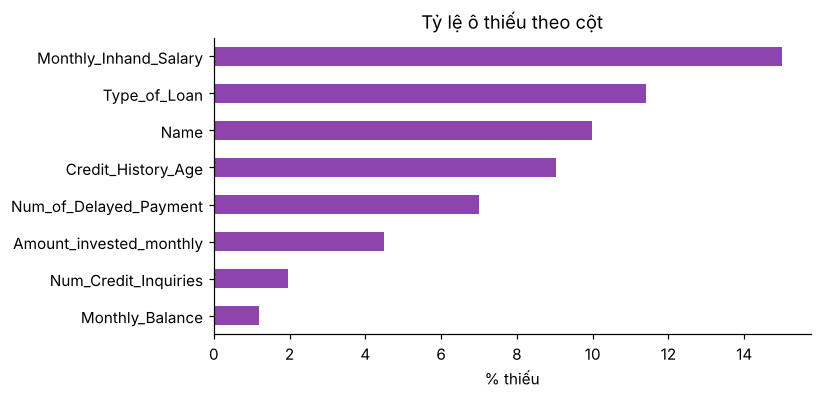

In [4]:
missing = pd.DataFrame({'số ô thiếu': df.isna().sum(), '% thiếu': (df.isna().mean() * 100).round(2)})
missing = missing[missing['số ô thiếu'] > 0].sort_values('số ô thiếu', ascending=False)
display(missing)

ax = missing['% thiếu'].sort_values().plot(kind='barh', figsize=(7, 3.5), color='#8e44ad')
ax.set_xlabel('% thiếu')
ax.set_title('Tỷ lệ ô thiếu theo cột')
plt.show()

`Type_of_Loan` thiếu 11.408 ô. Đây có phải dữ liệu bị mất không? Ta xem thiếu theo từng khách và đối chiếu với `Num_of_Loan`:

In [5]:
def as_number(s):
    return pd.to_numeric(s.astype(str).str.strip('_'), errors='coerce')

per_customer = df.groupby('Customer_ID').agg(
    missing_months=('Type_of_Loan', lambda s: s.isna().sum()),
    num_loan=('Num_of_Loan', lambda s: as_number(s).median()))

print('Số tháng thiếu Type_of_Loan trong mỗi khách:', per_customer.missing_months.value_counts().to_dict())
print('Với khách thiếu cả 8 tháng, Num_of_Loan (trung vị) =',
      per_customer[per_customer.missing_months == 8].num_loan.value_counts().to_dict())

Số tháng thiếu Type_of_Loan trong mỗi khách: {0: 11074, 8: 1426}
Với khách thiếu cả 8 tháng, Num_of_Loan (trung vị) = {0.0: 1426}


Mỗi khách hoặc thiếu `Type_of_Loan` ở cả 8 tháng (1.426 khách), hoặc không thiếu tháng nào, và nhóm thiếu cả 8 tháng đều có `Num_of_Loan = 0`. Vậy ô trống ở cột này nghĩa là khách không có khoản vay nào, không phải dữ liệu bị mất. Ta sẽ điền `No Loan`, không điền bằng loại vay phổ biến nhất.

Tiếp theo, ô thiếu có liên quan đến nhãn không? Nếu ô thiếu xuất hiện ngẫu nhiên thì tỷ lệ nhãn ở các dòng thiếu phải giống các dòng còn lại. Dùng kiểm định χ²:

In [6]:
rows = []
base_share = df.Credit_Score.value_counts(normalize=True).reindex(LABELS)
for col in missing.index:
    table = pd.crosstab(df[col].isna(), df.Credit_Score)
    _, p_value, _, _ = stats.chi2_contingency(table)
    share_when_missing = (table.loc[True] / table.loc[True].sum()).reindex(LABELS)
    rows.append({'cột': col,
                 'p-value χ²': round(p_value, 3),
                 'lệch tối đa tỷ lệ nhãn (điểm %)': round((share_when_missing - base_share).abs().max() * 100, 2)})
pd.DataFrame(rows).set_index('cột')

,p-value χ²,lệch tối đa tỷ lệ nhãn (điểm %)
cột,,
Monthly_Inhand_Salary,0.118,0.60
Type_of_Loan,0.000,17.29
Name,0.543,0.40
Credit_History_Age,0.881,0.25
Num_of_Delayed_Payment,0.795,0.35
Amount_invested_monthly,0.209,1.29
Num_Credit_Inquiries,0.700,0.92
Monthly_Balance,0.027,2.84


Ở 7 trong 8 cột, tỷ lệ nhãn của các dòng thiếu chỉ lệch tối đa khoảng 1,3 điểm phần trăm so với phần còn lại (p lớn hơn 0,05, riêng `Monthly_Balance` lệch 2,8 điểm). Nghĩa là ô thiếu gần như không phụ thuộc vào nhãn, nên điền thiếu không gây lệch theo nhãn, và thí nghiệm "che 10% giá trị" ở notebook 2 là một cách đo hợp lý.

`Type_of_Loan` là ngoại lệ (lệch 17 điểm, p gần 0). Điều này đúng như phân tích ở trên: ô trống nghĩa là không có khoản vay, bản thân điều đó có liên quan đến nhãn. Vì thế phải giữ nó thành một giá trị riêng (`No Loan`).

## 1.4 Chất lượng dữ liệu, chiều 2: đúng định dạng (kiểu dữ liệu và giá trị giả)
### 1.4.1 Cột số bị lưu thành chữ

In [7]:
print(df.dtypes.astype(str).value_counts().to_string(), '\n')

def not_a_number(s):
    return ~s.astype(str).str.fullmatch(r'-?\d+(\.\d+)?')

rows = []
for col in cc.NUMERIC_TEXT_COLS:
    values = df[col].dropna()
    bad = values[not_a_number(values)]
    rows.append({'cột': col,
                 'dtype': str(df[col].dtype),
                 'ô không phải số': len(bad),
                 'ô chứa "_"': int(values.astype(str).str.contains('_').sum()),
                 'ví dụ': bad.value_counts().head(3).index.tolist()})
pd.DataFrame(rows).set_index('cột')

str        20
float64     4
int64       4 



,dtype,ô không phải số,"ô chứa ""_""",ví dụ
cột,,,,
Age,str,4939,4939,"[24_, 38_, 29_]"
Annual_Income,str,6980,6980,"[14388.79_, 42904.26_, 9275.95_]"
Num_of_Loan,str,4785,4785,"[2_, 4_, 3_]"
Num_of_Delayed_Payment,str,2744,2744,"[8_, 15_, 10_]"
Changed_Credit_Limit,str,2091,2091,[_]
Outstanding_Debt,str,1009,1009,"[396.97_, 1054.86_, 761.18_]"
Amount_invested_monthly,str,4305,4305,[__10000__]
Monthly_Balance,str,9,9,[__-333333333333333333333333333__]


Các cột như `Age`, `Annual_Income` lẽ ra là số nhưng đang là chuỗi, vì có dấu `_` dính vào (`'24_'`, `'14388.79_'`). Ta kiểm tra giả thuyết "dấu `_` ở đầu hoặc cuối là nguyên nhân duy nhất": bỏ `_` rồi ép kiểu số, ngoài các giá trị giả đã biết còn ô nào không đọc được không?

In [8]:
rows = []
for col in cc.NUMERIC_TEXT_COLS:
    stripped = pd.to_numeric(df[col].astype('string').str.replace(r'^_+|_+$', '', regex=True), errors='coerce')
    is_known_placeholder = df[col] == cc.PLACEHOLDERS.get(col, '@@')
    unreadable = df[col].notna() & stripped.isna() & ~is_known_placeholder
    rows.append({'cột': col, 'ô còn không đọc được sau khi bỏ "_" (trừ giá trị giả)': int(unreadable.sum())})
pd.DataFrame(rows).set_index('cột')

,"ô còn không đọc được sau khi bỏ ""_"" (trừ giá trị giả)"
cột,
Age,0
Annual_Income,0
Num_of_Loan,0
Num_of_Delayed_Payment,0
Changed_Credit_Limit,0
Outstanding_Debt,0
Amount_invested_monthly,0
Monthly_Balance,0


Kết quả là 0 ở mọi cột, nên chỉ cần bỏ dấu `_` là ép kiểu được. Việc này làm ở notebook 2, sau khi đã xử lý giá trị giả.

### 1.4.2 Giá trị giả (placeholder)
Giá trị giả là giá trị trông như dữ liệu nhưng không có nghĩa. Ta tìm bằng ba cách độc lập:
1. Ở cột phân loại, quét các chuỗi không chứa chữ cái nào (giá trị thật như `Lawyer` hay `Low_spent_Small_value_payments` luôn có chữ).
2. Kiểm tra định dạng (SSN phải có dạng `ddd-dd-dddd`).
3. Ở cột số liên tục, tìm giá trị lặp lại bất thường (một số thực không thể lặp hàng nghìn lần), và giá trị lớn đến mức không thể có.

In [9]:
# Cách 1: chuỗi không chứa chữ cái ở cột phân loại
symbol_only = {}
for col in ['Name', 'Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Type_of_Loan']:
    values = df[col].dropna().astype(str)
    hits = values[values.str.fullmatch(r'[^A-Za-z]+')].value_counts()
    if len(hits):
        symbol_only[col] = hits.to_dict()
print('Cách 1, chuỗi không chứa chữ cái:', symbol_only)

# Cách 2: SSN có đúng định dạng không
ssn = df.SSN.dropna()
bad_ssn = ssn[~ssn.str.fullmatch(r'\d{3}-\d{2}-\d{4}')]
print('Cách 2, SSN sai định dạng:', len(bad_ssn), 'dòng, các giá trị khác nhau:', bad_ssn.unique().tolist())

# Cách 3: giá trị lặp nhiều nhất ở cột số
rows = []
for col in ['Amount_invested_monthly', 'Monthly_Balance', 'Changed_Credit_Limit', 'Outstanding_Debt',
            'Annual_Income', 'Monthly_Inhand_Salary']:
    counts = df[col].dropna().astype(str).value_counts()
    rows.append({'cột': col, 'giá trị lặp nhiều nhất': counts.index[0],
                 'số lần': int(counts.iloc[0]), 'số lần của giá trị thứ 2': int(counts.iloc[1])})
print('\nCách 3, giá trị lặp nhiều nhất của từng cột số:')
pd.DataFrame(rows).set_index('cột')

Cách 1, chuỗi không chứa chữ cái: {'Occupation': {'_______': 7062}, 'Credit_Mix': {'_': 20195}, 'Payment_Behaviour': {'!@9#%8': 7600}}
Cách 2, SSN sai định dạng: 5572 dòng, các giá trị khác nhau: ['#F%$D@*&8']



Cách 3, giá trị lặp nhiều nhất của từng cột số:


,giá trị lặp nhiều nhất,số lần,số lần của giá trị thứ 2
cột,,,
Amount_invested_monthly,__10000__,4305,169
Monthly_Balance,__-333333333333333333333333333__,9,1
Changed_Credit_Limit,_,2091,133
Outstanding_Debt,1360.45,24,23
Annual_Income,17273.83,16,16
Monthly_Inhand_Salary,6082.1875,15,15


In [10]:
# Cách 3 (tiếp): độ lớn không thể có ở Monthly_Balance
balance = pd.to_numeric(df.Monthly_Balance.astype('string').str.replace(r'^_+|_+$', '', regex=True), errors='coerce')
print('Monthly_Balance: nhỏ nhất =', balance.min(), '| phân vị 1% =', balance.quantile(.01).round(1),
      '| số dòng nhỏ hơn -1e6:', int((balance < -1e6).sum()))

Monthly_Balance: nhỏ nhất = -3.333333333333333e+26 | phân vị 1% = 67.7 | số dòng nhỏ hơn -1e6: 9


In [11]:
placeholder_table = pd.DataFrame([
    {'cột': col, 'giá trị giả': token, 'số dòng': int((df[col] == token).sum()),
     '% dòng': round((df[col] == token).mean() * 100, 2)}
    for col, token in cc.PLACEHOLDERS.items()]).set_index('cột')
placeholder_table

,giá trị giả,số dòng,% dòng
cột,,,
SSN,#F%$D@*&8,5572,5.57
Occupation,_______,7062,7.06
Credit_Mix,_,20195,20.20
Payment_Behaviour,!@9#%8,7600,7.60
Changed_Credit_Limit,_,2091,2.09
Amount_invested_monthly,__10000__,4305,4.30
Monthly_Balance,__-333333333333333333333333333__,9,0.01


Có 7 cột chứa giá trị giả:

| Cột | Giá trị giả | Phát hiện bằng cách nào |
|---|---|---|
| `SSN` | `#F%$D@*&8` | sai định dạng SSN |
| `Occupation` | `_______` | không chứa chữ cái |
| `Credit_Mix` | `_` | không chứa chữ cái |
| `Payment_Behaviour` | `!@9#%8` | không chứa chữ cái |
| `Changed_Credit_Limit` | `_` | không ép được sang số |
| `Amount_invested_monthly` | `__10000__` | lặp 4.305 lần, nhiều gấp hàng chục lần giá trị thứ hai |
| `Monthly_Balance` | `__-333…333__` | độ lớn khoảng −3·10²⁶, không thể là số dư tài khoản |

Cần để ý một bẫy: nếu chỉ bỏ dấu `_` thì `__10000__` thành số 10000 và trông như thật, lại còn là giá trị lặp nhiều nhất của cột. Vì vậy thứ tự bắt buộc là nhận diện giá trị giả trước, ép kiểu số sau.

Giá trị giả chiếm tỷ lệ lớn ở vài cột (`Credit_Mix` 20%). Những dòng có giá trị giả có phải một nhóm đặc biệt về nhãn không? Nếu có thì không được bỏ qua hoặc gộp bừa:

In [12]:
rows = []
for col in ['Credit_Mix', 'Occupation', 'Payment_Behaviour']:
    is_fake = df[col] == cc.PLACEHOLDERS[col]
    table = pd.crosstab(is_fake, df.Credit_Score)
    _, p_value, _, _ = stats.chi2_contingency(table)
    share = (table.loc[True] / table.loc[True].sum()).reindex(LABELS)
    rows.append({'cột': col, '% dòng là giá trị giả': round(is_fake.mean() * 100, 1), 'p-value χ²': round(p_value, 4),
                 **{f'%{k} trong nhóm giá trị giả': round(v * 100, 1) for k, v in share.items()}})

overall = (df.Credit_Score.value_counts(normalize=True).reindex(LABELS) * 100).round(1)
print('Tỷ lệ nhãn chung:', overall.to_dict())
pd.DataFrame(rows).set_index('cột')

Tỷ lệ nhãn chung: {'Poor': 29.0, 'Standard': 53.2, 'Good': 17.8}


,% dòng là giá trị giả,p-value χ²,%Poor trong nhóm giá trị giả,%Standard trong nhóm giá trị giả,%Good trong nhóm giá trị giả
cột,,,,,
Credit_Mix,20.2,0.8449,29.1,53.0,17.9
Occupation,7.1,0.7127,28.8,53.6,17.6
Payment_Behaviour,7.6,0.4728,29.3,52.5,18.2


Ở cả ba cột, nhóm giá trị giả có tỷ lệ nhãn gần bằng tỷ lệ chung, nên giá trị giả là nhiễu ngẫu nhiên, không mang thông tin về nhãn. Do đó có thể khôi phục giá trị thật (nếu cột không đổi theo khách) mà không làm mất tín hiệu nào.

## 1.5 Chất lượng dữ liệu, chiều 3: giá trị vô lý
Từ đây phân tích trên dữ liệu đã bỏ giá trị giả và ép kiểu số. Biến `view` chỉ để quan sát, `df` gốc không bị sửa.

In [13]:
view = cc.strip_numeric_text(cc.mark_placeholders(cc.add_month_num(df)))

NUM_COLS = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate',
            'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
            'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Total_EMI_per_month',
            'Amount_invested_monthly', 'Monthly_Balance']

view[NUM_COLS].describe(percentiles=[.01, .5, .99]).T[['count', 'min', '1%', '50%', '99%', 'max']].round(1)

,count,min,1%,50%,99%,max
Age,100000.0,-500.0,14.0,33.0,4112.1,8698.0
Annual_Income,100000.0,7005.9,7536.0,37578.6,179987.3,24198062.0
Monthly_Inhand_Salary,84998.0,303.6,531.9,3093.7,13814.9,15204.6
Num_Bank_Accounts,100000.0,-1.0,0.0,6.0,445.0,1798.0
Num_Credit_Card,100000.0,0.0,1.0,5.0,849.0,1499.0
Interest_Rate,100000.0,1.0,1.0,13.0,2865.0,5797.0
Num_of_Loan,100000.0,-100.0,-100.0,3.0,9.0,1496.0
Delay_from_due_date,100000.0,-5.0,0.0,18.0,61.0,67.0
Num_of_Delayed_Payment,92998.0,-3.0,0.0,14.0,27.0,4397.0
Changed_Credit_Limit,97909.0,-6.5,-1.5,9.4,28.8,37.0


Nhiều cột có `max` lớn gấp hàng nghìn lần phân vị 99%, hoặc có `min` âm ở cột đếm: tuổi từ −500 đến 8.698, số tài khoản tới 1.798, lãi suất tới 5.797%, `Num_of_Loan` bằng −100. Đây không phải đặc điểm thật của dữ liệu. Vấn đề là vạch ranh giới "hợp lệ" ở đâu, và vạch bằng cách nào cho có cơ sở.

### 1.5.1 Cách 1: luật tần suất cho cột đếm
Giá trị thật của một cột đếm xuất hiện rất nhiều lần (ví dụ "7 tài khoản" có hàng chục nghìn dòng), còn giá trị rác là số ngẫu nhiên nên mỗi giá trị chỉ xuất hiện vài lần. Luật như sau: lấy "thân" của phân phối, là đoạn giá trị nguyên liền nhau mà mỗi giá trị xuất hiện ít nhất 50 lần và chứa giá trị phổ biến nhất. Hai đầu của đoạn này là miền hợp lệ. Với cột đếm, cận dưới tối thiểu là 0 vì số đếm không thể âm.

In [14]:
MIN_COUNT = 50
COUNT_COLS = ['Num_Bank_Accounts', 'Num_Credit_Card', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries']

domain_found = {}
rows = []
for col in ['Age', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
            'Num_of_Delayed_Payment', 'Num_Credit_Inquiries']:
    counts = view[col].dropna().round().astype(int).value_counts().sort_index()
    low, high = body_run(counts, MIN_COUNT)
    if col in COUNT_COLS:
        low = max(low, 0)
    domain_found[col] = (int(low), int(high))

    outside = counts[(counts.index < low) | (counts.index > high)]
    most_repeated = outside.sort_values(ascending=False).head(1)
    rows.append({'cột': col,
                 'miền hợp lệ tìm được': f'[{low}, {high}]',
                 'dòng ngoài miền': int(outside.sum()),
                 'số giá trị rác khác nhau': len(outside),
                 'giá trị ngoài miền lặp nhiều nhất': f'{most_repeated.index[0]} ({int(most_repeated.iloc[0])} lần)' if len(most_repeated) else '-'})
pd.DataFrame(rows).set_index('cột')

,miền hợp lệ tìm được,dòng ngoài miền,số giá trị rác khác nhau,giá trị ngoài miền lặp nhiều nhất
cột,,,,
Age,"[14, 56]",2781,1685,-500 (886 lần)
Num_Bank_Accounts,"[0, 10]",1345,932,-1 (21 lần)
Num_Credit_Card,"[1, 10]",2320,1169,11 (36 lần)
Interest_Rate,"[1, 34]",2034,1716,498 (4 lần)
Num_of_Loan,"[0, 9]",4348,404,-100 (3876 lần)
Num_of_Delayed_Payment,"[0, 28]",1380,682,-1 (316 lần)
Num_Credit_Inquiries,"[0, 17]",1650,1205,1230 (4 lần)


Hai điều đáng chú ý ở cột cuối:
- `Age` có giá trị −500 lặp 886 lần và `Num_of_Loan` có −100 lặp 3.876 lần. Số nguyên ngẫu nhiên không thể lặp nhiều như vậy, nên đây là giá trị giả nằm trong cột số, cùng loại với `__10000__` ở mục 1.4.2. Chúng không thuộc "thân" phân phối vì không nằm trong đoạn giá trị liền nhau.
- `Num_of_Delayed_Payment` có các giá trị âm (−1, −2, −3) xuất hiện hàng trăm lần. Số lần trả chậm không thể âm, nên cận dưới đặt là 0.

Các giá trị rác còn lại chỉ lặp vài lần mỗi giá trị, đúng như số ngẫu nhiên.

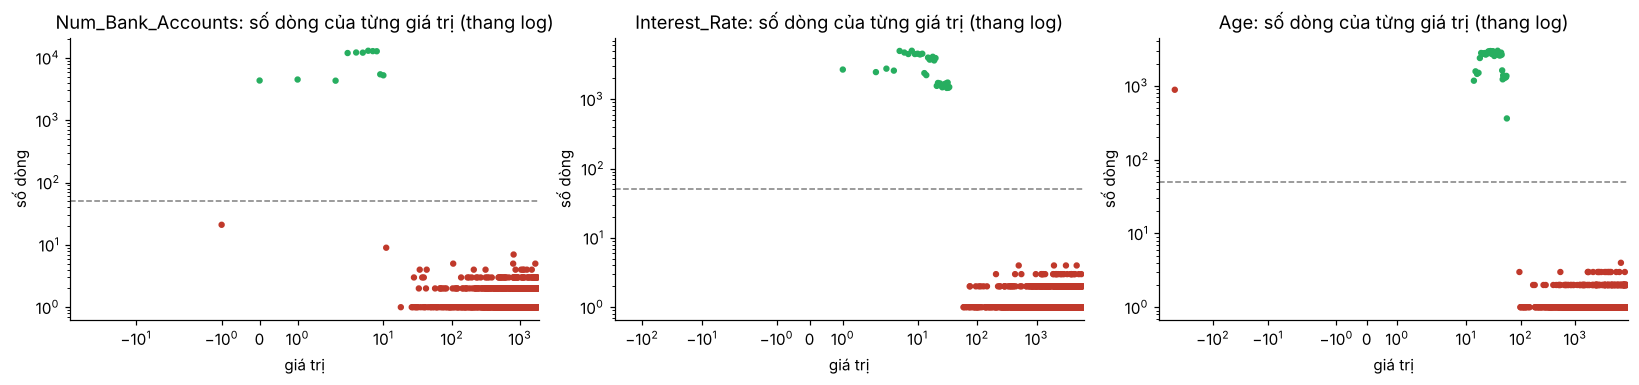

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, col in zip(ax, ['Num_Bank_Accounts', 'Interest_Rate', 'Age']):
    low, high = domain_found[col]
    counts = view[col].dropna().value_counts().sort_index()
    inside = [low <= v <= high for v in counts.index]
    a.scatter(counts.index, counts.values, s=10, c=['#27ae60' if ok else '#c0392b' for ok in inside])
    a.set_yscale('log')
    a.set_xscale('symlog')
    a.axhline(MIN_COUNT, ls='--', c='gray', lw=1)
    a.set_title(f'{col}: số dòng của từng giá trị (thang log)')
    a.set_xlabel('giá trị')
    a.set_ylabel('số dòng')
plt.tight_layout()
plt.show()

Trên biểu đồ, phần "thân" (màu xanh) gồm các giá trị lặp hàng nghìn lần, rồi số lần xuất hiện tụt đột ngột xuống phần "đuôi" (màu đỏ) chỉ còn 1 đến 4 lần mỗi giá trị. Đó là dấu hiệu của nhiễu ngẫu nhiên. So sánh miền tìm được với miền khai báo trong module:

In [16]:
print('Miền tìm được từ dữ liệu    :', domain_found)
print('Miền khai báo trong module  :', cc.DOMAIN)
assert domain_found == cc.DOMAIN, 'Miền trong module phải trùng với miền tìm được ở EDA'
print('Hai bên trùng nhau')

Miền tìm được từ dữ liệu    : {'Age': (14, 56), 'Num_Bank_Accounts': (0, 10), 'Num_Credit_Card': (1, 10), 'Interest_Rate': (1, 34), 'Num_of_Loan': (0, 9), 'Num_of_Delayed_Payment': (0, 28), 'Num_Credit_Inquiries': (0, 17)}
Miền khai báo trong module  : {'Age': (14, 56), 'Num_Bank_Accounts': (0, 10), 'Num_Credit_Card': (1, 10), 'Interest_Rate': (1, 34), 'Num_of_Loan': (0, 9), 'Num_of_Delayed_Payment': (0, 28), 'Num_Credit_Inquiries': (0, 17)}
Hai bên trùng nhau


### 1.5.2 Cách 2: kiểu số của giá trị rác ở `Total_EMI_per_month`
`Total_EMI_per_month` thật là số thực có nhiều chữ số lẻ (ví dụ `49.574949…`). Giả thuyết: giá trị rác là số nguyên, vì được sinh theo cách khác với dữ liệu thật. Để kiểm tra, tách các giá trị dương thành hai nhóm (là số nguyên hay không) và so sánh độ lớn.

In [17]:
emi = view.Total_EMI_per_month.dropna()
positive = emi[emi > 0]
is_whole = positive == positive.round(0)

pd.DataFrame({'số dòng': [int((~is_whole).sum()), int(is_whole.sum())],
              'nhỏ nhất': [positive[~is_whole].min(), positive[is_whole].min()],
              'trung vị': [positive[~is_whole].median(), positive[is_whole].median()],
              'lớn nhất': [positive[~is_whole].max(), positive[is_whole].max()]},
             index=['số thực (có phần lẻ)', 'số nguyên dương']).round(1)

,số dòng,nhỏ nhất,trung vị,lớn nhất
số thực (có phần lẻ),86223,4.5,76.8,1779.1
số nguyên dương,3164,845.0,41070.0,82331.0


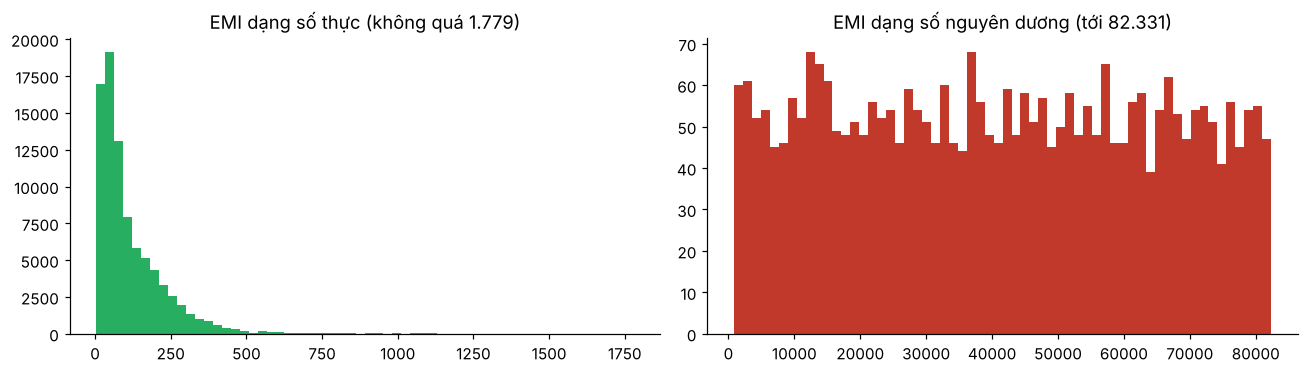

Số dòng EMI = 0 (khách không trả góp): 10613 (hợp lệ, không phải rác)


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(positive[~is_whole].clip(upper=2000), bins=60, color='#27ae60')
ax[0].set_title('EMI dạng số thực (không quá 1.779)')
ax[1].hist(positive[is_whole], bins=60, color='#c0392b')
ax[1].set_title('EMI dạng số nguyên dương (tới 82.331)')
plt.tight_layout()
plt.show()
print('Số dòng EMI = 0 (khách không trả góp):', int((emi == 0).sum()), '(hợp lệ, không phải rác)')

EMI hợp lệ có phần lẻ dài và không vượt quá 1.779. Cả 3.164 giá trị nguyên dương (trung vị khoảng 41.000, rải đến 82.331) đều là rác. Luật: EMI lớn hơn 1800 hoặc là số nguyên dương thì không hợp lệ. Giá trị 0 vẫn hợp lệ (khách không trả góp).

### 1.5.3 Cách 3: so với chính khách đó, ở `Annual_Income`
Thu nhập thật không đổi trong 8 tháng. Ta đo độ lệch tương đối của từng giá trị so với trung vị của chính khách đó:

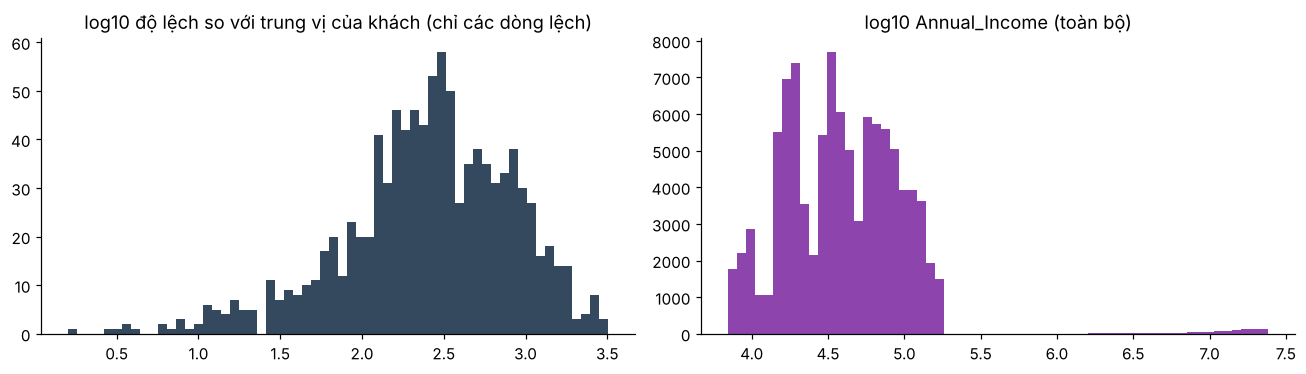

Số dòng không lệch (bằng đúng trung vị của khách): 99001
Số dòng lệch hơn 50%: 999 | số dòng lệch trong khoảng (0, 50%]: 0
Trong các giá trị lệch hơn 50%, tỷ lệ là số nguyên: 1.0


In [19]:
customer_median = view.groupby('Customer_ID').Annual_Income.transform('median')
deviation = (view.Annual_Income / customer_median - 1).abs()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(np.log10(deviation[deviation > 0] + 1e-9), bins=60, color='#34495e')
ax[0].set_title('log10 độ lệch so với trung vị của khách (chỉ các dòng lệch)')
ax[1].hist(np.log10(view.Annual_Income.dropna()), bins=60, color='#8e44ad')
ax[1].set_title('log10 Annual_Income (toàn bộ)')
plt.tight_layout()
plt.show()

far = deviation > 0.5
print('Số dòng không lệch (bằng đúng trung vị của khách):', int((deviation == 0).sum()))
print('Số dòng lệch hơn 50%:', int(far.sum()), '| số dòng lệch trong khoảng (0, 50%]:', int(((deviation > 0) & ~far).sum()))
print('Trong các giá trị lệch hơn 50%, tỷ lệ là số nguyên:', (view.Annual_Income[far] == view.Annual_Income[far].round(0)).mean().round(3))

Độ lệch hoặc bằng 0 (giá trị đúng), hoặc rất lớn (rác, lệch nhiều bậc độ lớn, và hầu hết là số nguyên, cùng đặc điểm với EMI rác). Gần như không có vùng lệch vừa phải. Luật: lệch hơn 50% so với trung vị của chính khách thì không hợp lệ (999 dòng).

### 1.5.4 Vì sao không dùng một luật IQR chung cho mọi cột?
Cách phổ biến là loại mọi giá trị nằm ngoài `Q3 + k·IQR`. Ta xem luật này sẽ xóa những gì ở các cột không có rác (sau khi đã bỏ giá trị giả):

In [20]:
rows = []
for col in ['Amount_invested_monthly', 'Monthly_Balance', 'Changed_Credit_Limit', 'Delay_from_due_date',
            'Outstanding_Debt', 'Monthly_Inhand_Salary', 'Credit_Utilization_Ratio']:
    s = view[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    def outside(k):
        return int(((s > q3 + k * iqr) | (s < q1 - k * iqr)).sum())
    rows.append({'cột': col, 'max': round(s.max(), 1), 'phân vị 99,9%': round(s.quantile(.999), 1),
                 'max / phân vị 99,9%': round(s.max() / s.quantile(.999), 2),
                 'IQR k=1,5 sẽ xóa': outside(1.5), 'IQR k=3 sẽ xóa': outside(3)})
pd.DataFrame(rows).set_index('cột')

,max,"phân vị 99,9%","max / phân vị 99,9%","IQR k=1,5 sẽ xóa",IQR k=3 sẽ xóa
cột,,,,,
Amount_invested_monthly,1977.3,1441.1,1.37,7568,2779
Monthly_Balance,1602.0,1398.3,1.15,7627,1555
Changed_Credit_Limit,37.0,32.5,1.14,668,0
Delay_from_due_date,67.0,65.0,1.03,4002,0
Outstanding_Debt,4998.1,4975.6,1.00,5272,0
Monthly_Inhand_Salary,15204.6,14880.4,1.02,1683,0
Credit_Utilization_Ratio,50.0,45.6,1.10,4,0


Ở 7 cột này, `max` chỉ ngang phân vị 99,9% (tỷ lệ 1,0 đến 1,4), nên không có đuôi rác tách biệt. Phần "ngoại lệ" theo IQR chỉ là đuôi lệch phải thật của phân phối thu nhập và số dư. Nếu áp IQR chung sẽ xóa nhầm hàng nghìn giá trị đúng, nhất là ở `Amount_invested_monthly` và `Monthly_Balance`. Vì vậy chỉ áp luật loại bỏ cho các cột có bằng chứng bị rác (mục 1.5.1 đến 1.5.3).

## 1.6 Chất lượng dữ liệu, chiều 4: nhất quán theo khách và giữa các cột
Dùng dữ liệu đã bỏ giá trị giả và giá trị rác (mục 1.5) để thấy cấu trúc thật của từng cột.

In [21]:
v3 = cc.mark_invalid(view)       # đã bỏ giá trị giả và giá trị vô lý, chưa điền gì
by_customer_v3 = v3.groupby('Customer_ID')

check_cols = ['SSN', 'Occupation', 'Name', 'Credit_Mix', 'Outstanding_Debt', 'Annual_Income', 'Interest_Rate',
              'Num_of_Loan', 'Age', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Total_EMI_per_month',
              'Monthly_Inhand_Salary', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries',
              'Delay_from_due_date', 'Credit_Utilization_Ratio', 'Amount_invested_monthly', 'Monthly_Balance',
              'Payment_Behaviour', 'Payment_of_Min_Amount']

distinct = pd.DataFrame({c: by_customer_v3[c].nunique().value_counts().sort_index() for c in check_cols}).T
distinct = distinct.fillna(0).astype(int)
distinct.columns = [f'{k} giá trị' for k in distinct.columns]
distinct

,1 giá trị,2 giá trị,3 giá trị,4 giá trị,5 giá trị,6 giá trị,7 giá trị,8 giá trị
SSN,12500,0,0,0,0,0,0,0
Occupation,12500,0,0,0,0,0,0,0
Name,12500,0,0,0,0,0,0,0
Credit_Mix,12500,0,0,0,0,0,0,0
Outstanding_Debt,12500,0,0,0,0,0,0,0
Annual_Income,12500,0,0,0,0,0,0,0
Interest_Rate,12500,0,0,0,0,0,0,0
Num_of_Loan,12500,0,0,0,0,0,0,0
Age,5302,7198,0,0,0,0,0,0
Num_Bank_Accounts,12200,300,0,0,0,0,0,0


Cách đọc bảng: mỗi hàng là một cột dữ liệu, mỗi ô là số khách có đúng *k* giá trị hợp lệ khác nhau trong 8 tháng.

Từ bảng, các cột chia thành ba loại (đây là kết quả kiểm tra dự đoán ở mục 1.1):
- Không đổi theo khách: `SSN`, `Occupation`, `Name`, `Credit_Mix`, `Outstanding_Debt`, `Annual_Income`, `Interest_Rate`, `Num_of_Loan`. Mọi khách chỉ có đúng 1 giá trị hợp lệ, nên một ô lỗi có thể khôi phục chính xác từ các tháng khác của cùng khách.
- Không đổi nhưng có vài bước nhảy: `Age` (đổi đúng 1 lần, thêm 1 tuổi), `Num_Bank_Accounts`, `Num_Credit_Card`, `Total_EMI_per_month`, `Monthly_Inhand_Salary`. Vài trăm khách có đúng 2 mức. Cần xem đây là lỗi hay thay đổi thật.
- Thay đổi theo tháng: các cột còn lại.

### Các bước nhảy là thay đổi thật hay là lỗi?

In [22]:
changed = {c: set(by_customer_v3[c].nunique()[lambda s: s > 1].index)
           for c in ['Num_Bank_Accounts', 'Num_Credit_Card', 'Total_EMI_per_month', 'Monthly_Inhand_Salary']}
print('Số khách có thay đổi:', {c: len(s) for c, s in changed.items()})
print('Khách đổi cả Num_Bank_Accounts và Num_Credit_Card :', len(changed['Num_Bank_Accounts'] & changed['Num_Credit_Card']))
print('Khách đổi cả Total_EMI_per_month và Monthly_Inhand_Salary:', len(changed['Total_EMI_per_month'] & changed['Monthly_Inhand_Salary']))

examples = (sorted(changed['Num_Bank_Accounts'])[:1] +
            sorted(changed['Monthly_Inhand_Salary'] - changed['Num_Bank_Accounts'])[:1])
for customer in examples:
    print(f'\n{customer}')
    display(v3.loc[v3.Customer_ID == customer,
                   ['Month', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Monthly_Inhand_Salary', 'Total_EMI_per_month']].T)

Số khách có thay đổi: {'Num_Bank_Accounts': 300, 'Num_Credit_Card': 296, 'Total_EMI_per_month': 772, 'Monthly_Inhand_Salary': 746}
Khách đổi cả Num_Bank_Accounts và Num_Credit_Card : 289
Khách đổi cả Total_EMI_per_month và Monthly_Inhand_Salary: 741

CUS_0x10dd


,16008,16009,16010,16011,16012,16013,16014,16015
Month,January,February,March,April,May,June,July,August
Num_Bank_Accounts,5.0,5.0,5.0,4.0,4.0,4.0,4.0,4.0
Num_Credit_Card,4.0,4.0,4.0,3.0,3.0,3.0,3.0,3.0
Monthly_Inhand_Salary,9090.8,9090.8,9090.8,9090.8,9090.8,9090.8,9090.8,9090.8
Total_EMI_per_month,315.406101,315.406101,315.406101,315.406101,315.406101,315.406101,315.406101,315.406101



CUS_0x105b


,5800,5801,5802,5803,5804,5805,5806,5807
Month,January,February,March,April,May,June,July,August
Num_Bank_Accounts,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
Num_Credit_Card,4.0,4.0,NaN,4.0,4.0,4.0,4.0,4.0
Monthly_Inhand_Salary,2575.0175,2575.0175,2575.0175,2575.0175,2575.0175,2289.5937,2289.5937,2289.5937
Total_EMI_per_month,0.0,0.0,0.0,NaN,0.0,285.4238,285.4238,285.4238


Các thay đổi đi theo cặp và chỉ xảy ra một lần, không dao động ngẫu nhiên: số tài khoản và số thẻ cùng đổi (hầu hết các trường hợp), lương và EMI cùng đổi. Đây là thay đổi thật (đổi việc, thêm hoặc đóng khoản vay), không phải lỗi.

Hệ quả cho cách điền thiếu: với các cột này, điền bằng mode hoặc trung vị của khách sẽ kéo giá trị của giai đoạn này sang giai đoạn khác. Điền bằng giá trị của tháng gần nhất sẽ đúng hơn. Điều này được đo bằng số ở notebook 2.

### Ràng buộc giữa các cột

In [23]:
# (1) Num_of_Loan phải bằng số loại vay liệt kê trong Type_of_Loan
has_loan_count = v3.Num_of_Loan.notna()
types_listed = v3.Type_of_Loan.map(cc.count_loan_types)
match = (types_listed[has_loan_count] == v3.Num_of_Loan[has_loan_count]).mean()
print(f'(1) Num_of_Loan bằng số loại vay trong Type_of_Loan: {match:.2%} ({has_loan_count.sum():,} dòng hợp lệ)')

# (2) Credit_History_Age phải tăng đúng 1 tháng mỗi tháng
months = v3.Credit_History_Age.map(cc.parse_history_months)
spread = (months - v3.Month_Num).groupby(v3.Customer_ID).agg(lambda s: s.max() - s.min())
print(f'(2) Credit_History_Age trừ thứ tự tháng là hằng số trong khách: {(spread == 0).mean():.2%} số khách')

# (3) Tuổi đổi tối đa 1 trong 8 tháng
age_range = by_customer_v3.Age.agg(lambda s: s.max() - s.min())
print('(3) Tuổi chênh tối đa trong khách:', age_range.value_counts().sort_index().to_dict())

# (4) Annual_Income xấp xỉ 12 lần Monthly_Inhand_Salary
ratio = (v3.Monthly_Inhand_Salary * 12 / v3.Annual_Income).dropna()
print(f'(4) 12 lần lương thực nhận chia thu nhập năm: trung vị {ratio.median():.3f}, '
      f'IQR [{ratio.quantile(.25):.3f}, {ratio.quantile(.75):.3f}], 1% đến 99% [{ratio.quantile(.01):.2f}, {ratio.quantile(.99):.2f}]')

(1) Num_of_Loan bằng số loại vay trong Type_of_Loan: 100.00% (95,652 dòng hợp lệ)


(2) Credit_History_Age trừ thứ tự tháng là hằng số trong khách: 100.00% số khách


(3) Tuổi chênh tối đa trong khách: {0.0: 5302, 1.0: 7198}
(4) 12 lần lương thực nhận chia thu nhập năm: trung vị 0.999, IQR [0.958, 1.039], 1% đến 99% [0.72, 1.30]


Kết luận từ các ràng buộc:
1. `Num_of_Loan` khớp 100% với số loại vay. Khi `Num_of_Loan` bị rác (4.348 dòng) có thể tính lại chính xác từ `Type_of_Loan` thay vì đoán.
2. `Credit_History_Age` tăng đúng 1 tháng mỗi tháng ở 100% khách. Các ô thiếu (9.030) khôi phục chính xác bằng phép cộng.
3. Tuổi đổi tối đa 1 (sinh nhật), khớp với miền tuổi 14 đến 56 và với cách điền theo tháng gần nhất.
4. 12 lần lương thực nhận so với thu nhập năm quanh 1 (trung vị 0,999, IQR từ 0,96 đến 1,04), nên hai cột này tương quan rất mạnh. Đây là bằng chứng độc lập cho thấy các giá trị thu nhập khổng lồ ở mục 1.5.3 là rác.

### Tên khách hàng
Nhiều `Name` có một chữ cái thường dính ở cuối (ví dụ `Ashleyh`, `Jessicad`). Đây là nhiễu ở cột định danh. Vì `Name` chỉ là mã nhận dạng và không dùng làm đặc trưng, ta giữ nguyên (chỉ điền ô thiếu theo khách) và ghi vào phần hạn chế.

In [24]:
names_per_customer = df.dropna(subset=['Name']).groupby('Customer_ID').Name.nunique()
print('Mỗi khách có đúng 1 Name (khi không thiếu):', bool((names_per_customer == 1).all()))
name_missing = df.groupby('Customer_ID').Name
print('Số khách thiếu Name ít nhất 1 tháng:', int(name_missing.apply(lambda s: s.isna().any()).sum()),
      '| số khách thiếu cả 8 tháng:', int(name_missing.apply(lambda s: s.isna().all()).sum()))
print(df.Name.dropna().drop_duplicates().sample(8, random_state=3).tolist())

Mỗi khách có đúng 1 Name (khi không thiếu): True


Số khách thiếu Name ít nhất 1 tháng: 7133 | số khách thiếu cả 8 tháng: 0
['Lucia Mutikaniy', 'Alwyn Scottg', 'Lindaz', 'enu', 'Katen', 'Yukhananovb', 'Maggiel', 'Lauren Tarab']


## 1.7 Quan hệ của từng cột với nhãn (trên giá trị hợp lệ)
Dùng `v3` (đã bỏ giá trị giả và giá trị rác, chưa điền thiếu). Mỗi đặc trưng được so sánh theo từng nhãn.

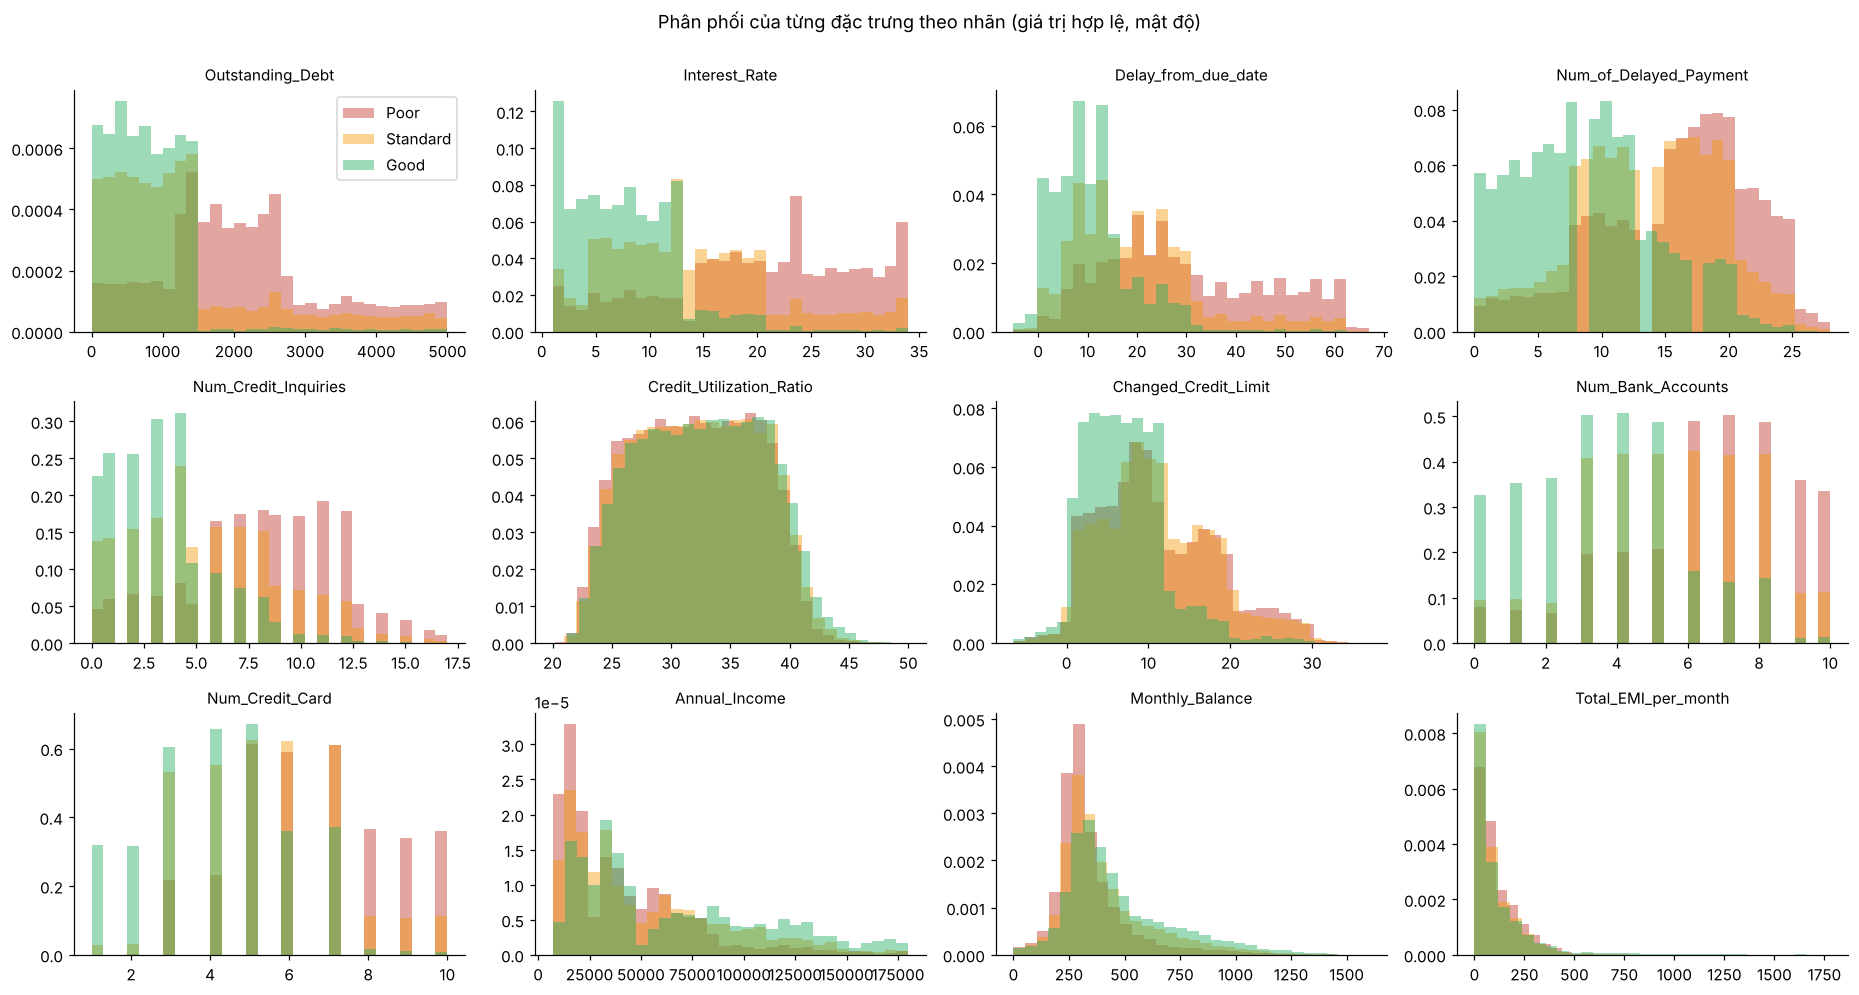

In [25]:
FEATURES_TO_PLOT = ['Outstanding_Debt', 'Interest_Rate', 'Delay_from_due_date', 'Num_of_Delayed_Payment',
                    'Num_Credit_Inquiries', 'Credit_Utilization_Ratio', 'Changed_Credit_Limit', 'Num_Bank_Accounts',
                    'Num_Credit_Card', 'Annual_Income', 'Monthly_Balance', 'Total_EMI_per_month']

fig, ax = plt.subplots(3, 4, figsize=(17, 9))
for a, col in zip(ax.ravel(), FEATURES_TO_PLOT):
    for label in LABELS:
        values = v3.loc[v3.Credit_Score == label, col].dropna()
        a.hist(values, bins=30, density=True, alpha=.45, color=COLORS[label], label=label)
    a.set_title(col, fontsize=10)
ax[0, 0].legend()
plt.suptitle('Phân phối của từng đặc trưng theo nhãn (giá trị hợp lệ, mật độ)', y=1.0)
plt.tight_layout()
plt.show()

Nhiều đặc trưng cho thấy ngưỡng tách khá rõ giữa các nhãn: `Outstanding_Debt` quanh 1.500, `Interest_Rate` quanh 14 và 20, `Num_of_Delayed_Payment` quanh 8 đến 10, `Num_Credit_Inquiries` quanh 5, và với `Num_Credit_Card` từ 8 trở lên gần như chỉ còn Poor và Standard. Tuy vậy các phân phối chồng lấn nhiều: một đặc trưng thường loại được một lớp chứ không xác định được nhãn. Ví dụ `Interest_Rate` từ 21 trở lên hầu như không còn Good (khoảng 1%) nhưng vẫn lẫn khoảng 34% Standard.

Điều này gợi ý bốn điều:
- Mô hình dạng cây hợp với dữ liệu này vì tín hiệu nằm ở các ngưỡng.
- Nhãn có nhiễu, nên không thể kỳ vọng độ chính xác rất cao (notebook 4 xác nhận).
- Dữ liệu có vẻ là dữ liệu mô phỏng, cần ghi vào phần hạn chế.
- Nếu làm sạch sai ở các cột này thì ngưỡng bị nhòe và mô hình mất tín hiệu.

`Credit_Utilization_Ratio`, `Occupation` và `Month` hầu như không phân biệt được các nhãn.

### Mức liên hệ với nhãn: kiểm định thống kê và độ lớn hiệu ứng
- Cột số: kiểm định Kruskal–Wallis (không cần giả định phân phối chuẩn) và độ lớn hiệu ứng ε² = H / (n − 1). Thêm hệ số Spearman với nhãn xếp thứ tự Poor < Standard < Good.
- Cột phân loại: kiểm định χ² và hệ số Cramér's V.

Với 100.000 dòng thì kiểm định nào cũng có ý nghĩa thống kê, nên độ lớn hiệu ứng đáng quan tâm hơn p-value.

In [26]:
numeric_features = [c for c in NUM_COLS if c != 'Num_of_Loan'] + ['Num_of_Loan']
effect_num = effect_numeric(v3, numeric_features).sort_values('ε² (Kruskal)', ascending=False)

CATEGORICAL_FEATURES = ['Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Occupation', 'Month']
effect_cat = pd.DataFrame({'Cramér V': {c: cramers_v(df[c].fillna('(thiếu)'), df.Credit_Score)
                                        for c in CATEGORICAL_FEATURES}}).sort_values('Cramér V', ascending=False)
display(effect_num.round(4))
display(effect_cat.round(4))

# lưu lại để notebook 3 so sánh trước và sau làm sạch
effect_num.to_csv('../data/reports/eda_effect_numeric_before.csv')
effect_cat.to_csv('../data/reports/eda_effect_categorical_before.csv')

,ε² (Kruskal),Spearman với nhãn,n hợp lệ
đặc trưng,,,
Interest_Rate,0.2334,-0.4809,97966
Delay_from_due_date,0.1946,-0.4379,100000
Outstanding_Debt,0.1940,-0.4338,100000
Num_Credit_Inquiries,0.1920,-0.4379,96385
Num_Bank_Accounts,0.1575,-0.3874,98655
Num_Credit_Card,0.1487,-0.3850,97680
Num_of_Delayed_Payment,0.1439,-0.3617,91618
Num_of_Loan,0.1248,-0.3531,95652
Changed_Credit_Limit,0.0534,-0.1573,97909


,Cramér V
Credit_Mix,0.4022
Payment_of_Min_Amount,0.3132
Payment_Behaviour,0.0846
Month,0.0318
Occupation,0.0292


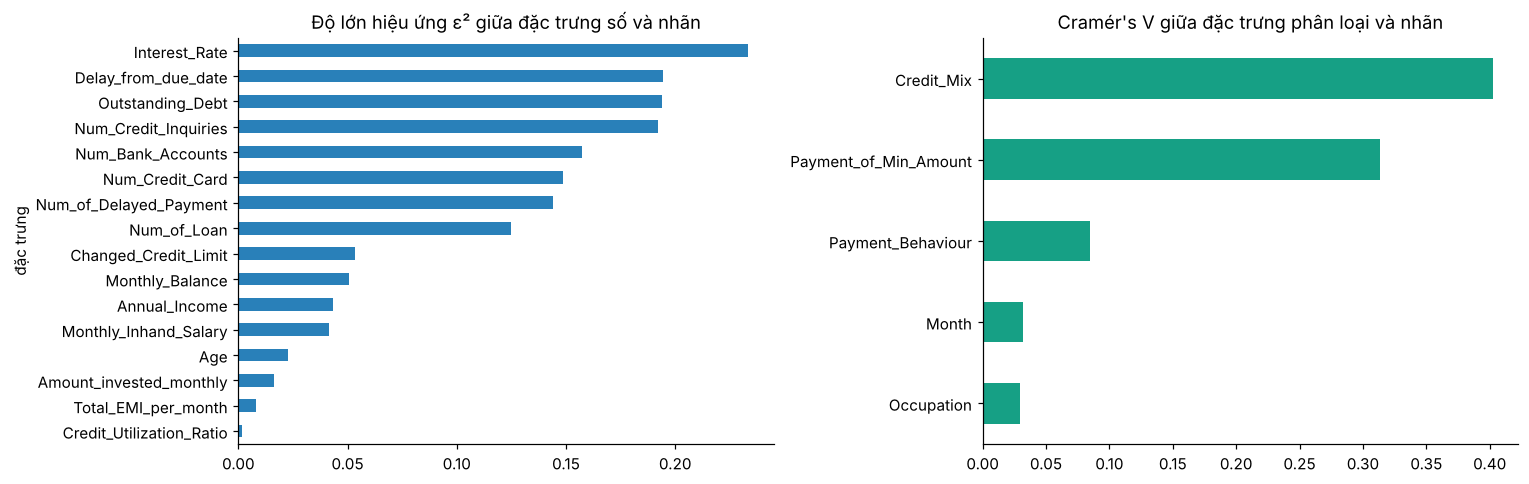

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
effect_num['ε² (Kruskal)'].sort_values().plot(kind='barh', ax=ax[0], color='#2980b9')
ax[0].set_title('Độ lớn hiệu ứng ε² giữa đặc trưng số và nhãn')
effect_cat['Cramér V'].sort_values().plot(kind='barh', ax=ax[1], color='#16a085')
ax[1].set_title("Cramér's V giữa đặc trưng phân loại và nhãn")
plt.tight_layout()
plt.show()

Các đặc trưng liên quan nhiều nhất tới nhãn đều thuộc nhóm nợ và thanh toán: lãi suất, độ trễ thanh toán, số lần trả chậm, dư nợ, số lần truy vấn tín dụng. Ở cột phân loại, `Credit_Mix` và `Payment_of_Min_Amount` có Cramér's V cao nhất, còn `Occupation` và `Month` gần như không liên quan tới nhãn.

Từ đó rút ra hai điều. Một là kết quả hợp lý với kiến thức về tín dụng, nên dữ liệu có tín hiệu thật. Hai là lỗi ở các cột mạnh (`Credit_Mix` có 20% giá trị giả, `Interest_Rate`, `Num_of_Delayed_Payment`) sẽ hại mô hình nhiều nhất, nên cần ưu tiên khôi phục chính xác các cột này.

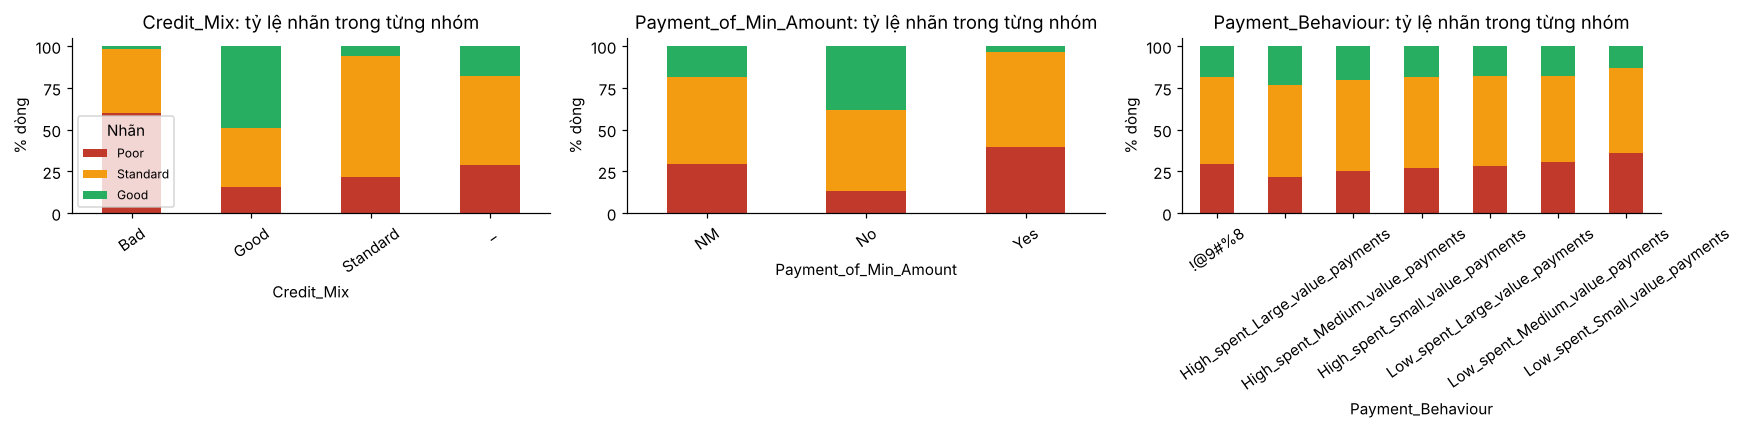

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ['Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']):
    share = pd.crosstab(df[col], df.Credit_Score, normalize='index')[LABELS] * 100
    share.plot(kind='bar', stacked=True, ax=a, color=[COLORS[k] for k in LABELS], rot=35, legend=False)
    a.set_ylabel('% dòng')
    a.set_title(col + ': tỷ lệ nhãn trong từng nhóm')
ax[0].legend(title='Nhãn', fontsize=8)
plt.tight_layout()
plt.show()

Với `Credit_Mix = Bad`, khoảng 60% dòng là Poor và chỉ 1,5% là Good. Với `Credit_Mix = Good`, gần một nửa (49%) là Good. Nhóm giá trị giả `_` thì có tỷ lệ nhãn giống tỷ lệ chung (đúng như kiểm định ở mục 1.4.2), nghĩa là thông tin vốn rất mạnh của cột này đang bị che mất ở 20% số dòng. Khôi phục nhóm này từ các tháng khác của cùng khách (vì `Credit_Mix` không đổi theo khách) rất đáng làm.

## 1.8 Tương quan giữa các đặc trưng số (Spearman)

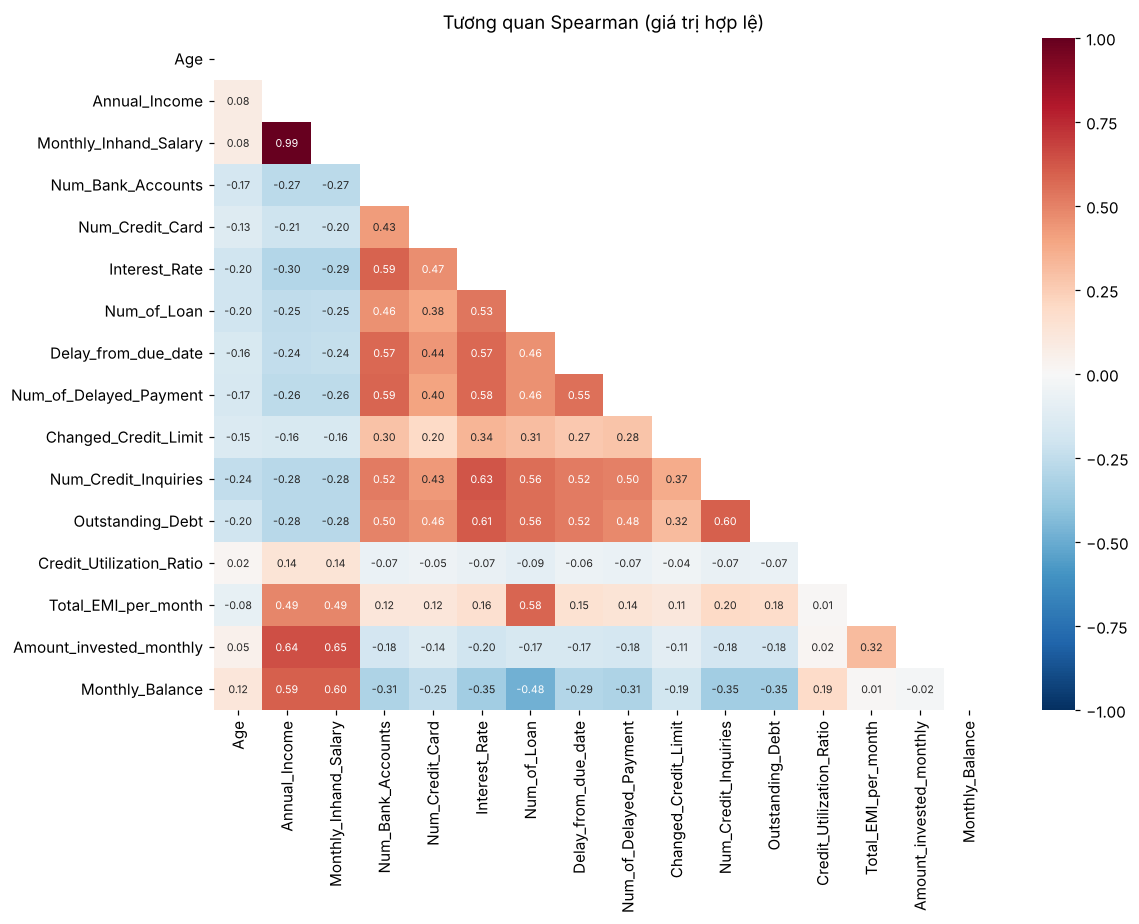

Các cặp đặc trưng có |ρ| > 0,7:


,,ρ
Monthly_Inhand_Salary,Annual_Income,0.994


In [29]:
corr = v3[NUM_COLS].corr(method='spearman')
upper = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, mask=upper, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, vmin=-1, vmax=1)
plt.title('Tương quan Spearman (giá trị hợp lệ)')
plt.tight_layout()
plt.show()

pairs = corr.where(~upper).stack()
pairs = pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False)
print('Các cặp đặc trưng có |ρ| > 0,7:')
pairs.round(3).to_frame('ρ')

Có ba nhóm quan hệ đáng chú ý:
1. `Annual_Income` và `Monthly_Inhand_Salary` tương quan 0,99 (đa cộng tuyến). Mô hình cây không bị ảnh hưởng, nhưng cần nhớ khi diễn giải mô hình tuyến tính.
2. Một cụm chỉ số rủi ro tín dụng (số tài khoản, số thẻ, lãi suất, số khoản vay, độ trễ, số lần trả chậm, truy vấn tín dụng, dư nợ) tương quan với nhau ở mức 0,4 đến 0,6.
3. `Amount_invested_monthly` và `Monthly_Balance` tương quan 0,6 đến 0,65 với lương và thu nhập, nhưng gần như không tương quan với nhau (−0,02). Vậy hai cột này đoán được từ các cột khác của cùng dòng, và đó là lý do thử điền thiếu bằng mô hình ở notebook 2.

Ngoài cặp thứ nhất, không có cặp nào đủ mạnh để phải bỏ cột.

## 1.9 Dữ liệu bẩn đến mức nào?
Đếm số ô và số dòng có ít nhất một vấn đề (thiếu, giá trị giả, sai kiểu, giá trị vô lý), để biết có thể xóa dòng lỗi được không.

Ô có vấn đề      : 135,774 / 2,800,000 (4.8%)
Dòng có >= 1 lỗi : 76,333 / 100,000 (76.3%)
Khách có >= 1 lỗi: 12,500 / 12,500


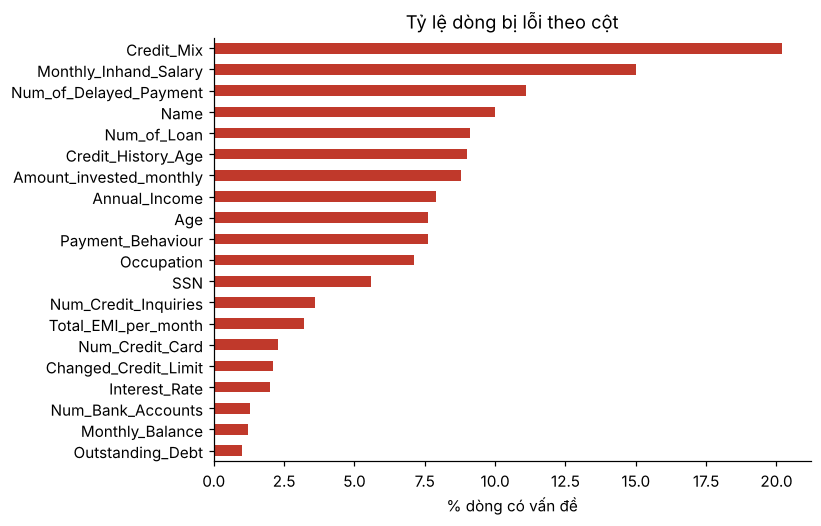

In [30]:
base = cc.add_month_num(df)
log = {}
after_placeholders = cc.mark_placeholders(base, log)
after_strip = cc.strip_numeric_text(after_placeholders)
after_invalid = cc.mark_invalid(after_strip, log)

# problem[ô] = True nếu ô đó có vấn đề
problem = df.isna().copy()
for col, token in cc.PLACEHOLDERS.items():
    problem[col] |= (df[col] == token)                                                  # giá trị giả
for col in cc.NUMERIC_TEXT_COLS:
    problem[col] |= df[col].astype(str).str.contains('_') & df[col].notna()             # số dính dấu "_"
for col in list(cc.DOMAIN) + ['Total_EMI_per_month', 'Annual_Income']:
    problem[col] |= after_invalid[col].isna() & after_strip[col].notna()                # giá trị vô lý
problem['Type_of_Loan'] = False        # ô trống nghĩa là không có khoản vay (mục 1.3), không tính là lỗi

cells_bad = int(problem.values.sum())
rows_bad = int(problem.any(axis=1).sum())
customers_bad = int(problem.any(axis=1).groupby(df.Customer_ID).any().sum())
print(f'Ô có vấn đề      : {cells_bad:,} / {problem.size:,} ({cells_bad / problem.size:.1%})')
print(f'Dòng có >= 1 lỗi : {rows_bad:,} / {len(df):,} ({rows_bad / len(df):.1%})')
print(f'Khách có >= 1 lỗi: {customers_bad:,} / {df.Customer_ID.nunique():,}')

bad_by_col = problem.sum().sort_values(ascending=False)
bad_by_col = bad_by_col[bad_by_col > 0]
(bad_by_col / len(df) * 100).round(1).sort_values().plot(kind='barh', figsize=(7, 5), color='#c0392b')
plt.xlabel('% dòng có vấn đề')
plt.title('Tỷ lệ dòng bị lỗi theo cột')
plt.show()

Đa số dòng có ít nhất một ô lỗi, và mọi khách đều có lỗi. Vì vậy xóa dòng lỗi không khả thi: gần hết dữ liệu mất đi và việc xóa có thể lệch theo khách hoặc theo nhãn. Bắt buộc phải sửa hoặc khôi phục các ô lỗi. Bảng dưới đây cũng là báo cáo chất lượng "trước làm sạch", sẽ dùng lại ở notebook 2.

In [31]:
import os
os.makedirs('../data/reports', exist_ok=True)

quality_before = pd.DataFrame({
    'dtype_goc': df.dtypes.astype(str),
    'thieu': df.isna().sum(),
    'placeholder': [int((df[c] == cc.PLACEHOLDERS[c]).sum()) if c in cc.PLACEHOLDERS else 0 for c in df.columns],
    'vo_ly': [int((after_invalid[c].isna() & after_strip[c].notna()).sum()) if c in after_invalid else 0 for c in df.columns],
    'dong_co_van_de': problem.sum(),
})
quality_before['%_dong_co_van_de'] = (quality_before['dong_co_van_de'] / len(df) * 100).round(2)
quality_before.to_csv('../data/reports/quality_before.csv')
quality_before[quality_before.dong_co_van_de > 0]

,dtype_goc,thieu,placeholder,vo_ly,dong_co_van_de,%_dong_co_van_de
Name,str,9985,0,0,9985,9.98
Age,str,0,0,2781,7635,7.64
SSN,str,0,5572,0,5572,5.57
Occupation,str,0,7062,0,7062,7.06
Annual_Income,str,0,0,999,7929,7.93
Monthly_Inhand_Salary,float64,15002,0,0,15002,15.00
Num_Bank_Accounts,int64,0,0,1345,1345,1.34
Num_Credit_Card,int64,0,0,2320,2320,2.32
Interest_Rate,int64,0,0,2034,2034,2.03
Num_of_Loan,str,0,0,4348,9108,9.11


## 1.10 Từ phát hiện đến quyết định làm sạch

| # | Vấn đề | Bằng chứng (mục) | Quyết định | Hàm trong `credit_cleaning.py` |
|---|---|---|---|---|
| 1 | 7 cột có giá trị giả | Ba cách phát hiện độc lập (1.4.2). Nhóm giá trị giả không mang thông tin nhãn | Đổi thành NaN trước khi ép kiểu | `mark_placeholders` |
| 2 | 8 cột số bị lưu thành chữ vì dính `_` | Bỏ `_` thì 0 ô còn lại không đọc được (1.4.1) | Bỏ `_` ở đầu và cuối rồi ép `float64` | `strip_numeric_text` |
| 3 | Cột đếm có giá trị ngoài miền | Số lần xuất hiện tụt đột ngột, miền lấy từ dữ liệu (1.5.1) | Ngoài miền thì thành NaN | `mark_invalid`, `DOMAIN` |
| 4 | EMI bị rác | Giá trị rác là số nguyên, EMI thật không quá 1.779 (1.5.2) | EMI lớn hơn 1800 hoặc là số nguyên dương thì thành NaN | `mark_invalid` |
| 5 | `Annual_Income` bị rác | Lệch hàng bậc độ lớn so với chính khách (1.5.3) | Lệch quá 50% so với trung vị của khách thì thành NaN | `mark_invalid` |
| 6 | Không dùng IQR chung | IQR xóa nhầm hàng nghìn giá trị thật ở 7 cột (1.5.4) | Chỉ áp luật cho cột có bằng chứng bị rác | không có |
| 7 | Cột không đổi theo khách | 1 giá trị mỗi khách, ở cả 12.500 khách (1.6) | Điền bằng mode hoặc trung vị của chính khách | `fill_categorical`, `fill_numeric` (cust_median) |
| 8 | Cột có bước nhảy thật | Đổi theo cặp và chỉ một lần (1.6) | Điền bằng giá trị của tháng gần nhất | `nearest_fill` |
| 9 | `Num_of_Loan` bị rác | Khớp 100% với số loại vay (1.6) | Tính lại từ `Type_of_Loan` | `rebuild_loan_count` |
| 10 | `Credit_History_Age` là chuỗi và có ô thiếu | Tăng đúng 1 tháng mỗi tháng ở 100% khách (1.6) | Đổi ra số tháng, ô thiếu tính bằng phép cộng | `parse_history_months`, `rebuild_credit_history` |
| 11 | `Type_of_Loan` thiếu | Thiếu đúng lúc `Num_of_Loan = 0` (1.3) | Điền `No Loan` | `repair` |
| 12 | `Amount_invested_monthly`, `Monthly_Balance` biến động mạnh | Phụ thuộc lương và thói quen chi tiêu (notebook 2) | Dùng mô hình dự đoán tỷ lệ so với lương (thắng dự đoán giá trị tuyệt đối trong thí nghiệm) | `model_fill` (ratio=True) |
| 13 | `Payment_Behaviour` đổi ngẫu nhiên theo tháng | Thí nghiệm ở notebook 2 | Giữ thành nhóm `Unknown` | `repair` |
| 14 | Xóa dòng lỗi không khả thi | Đa số dòng có ít nhất 1 lỗi (1.9) | Sửa hoặc khôi phục, không xóa | không có |
| 15 | Nhãn lệch lớp, dữ liệu theo khách | Mục 1.2 | Chia train và test theo khách, dùng macro-F1 | notebook 4 |

Notebook 2 thực hiện các quyết định này, đo lại từng quyết định bằng số (nhất là cách điền thiếu) và xuất `credit_clean.csv`.